## Baseline Logistic Regression
Uses `src/prep_data.py` and `src/evaluate_model.py` to prep data and evaluate each model.

In [1]:
import sys; sys.path.append("..")
import pandas as pd, matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from src.prep_data import get_splits
from src.evaluate_model import best_threshold, evaluate, full_report, time_series_cv

### 1. Load data, clean it, then split chronologically

In [2]:
data = get_splits()
X_train, y_train = data["X_train"], data["y_train"]
X_val,   y_val   = data["X_val"],   data["y_val"]
X_test,  y_test  = data["X_test"],  data["y_test"]
features = data["features"]

Dropped 26 columns: ['WSR0', 'WSR1', 'WSR2', 'WSR3', 'WSR4', 'WSR5', 'WSR6', 'WSR7', 'WSR8', 'WSR9', 'WSR10', 'WSR11', 'WSR12', 'WSR13', 'WSR14', 'WSR15', 'WSR16', 'WSR17', 'WSR18', 'WSR19', 'WSR20', 'WSR21', 'WSR22', 'WSR23', 'WSR_PK', 'WSR_AV']
Dropped 593 rows (23.4%); 1941 rows and 46 features remain
train  1358 rows  1998-01-01 -> 2003-01-16  ozone-day rate: 0.080
val     291 rows  2003-01-17 -> 2004-01-20  ozone-day rate: 0.055
test    292 rows  2004-01-21 -> 2004-12-31  ozone-day rate: 0.017


### 2. Fit the model
Since ozone days are rare, utilize `class_weight="balanced"` to compensate.

In [3]:
model = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
])
model.fit(X_train, y_train)

p_train = model.predict_proba(X_train)[:, 1]
p_val   = model.predict_proba(X_val)[:, 1]
evaluate("train", y_train, p_train)
evaluate("val  ", y_val, p_val);

train: ROC-AUC=0.923  PR-AUC=0.494  F1@0.50=0.449
val  : ROC-AUC=0.884  PR-AUC=0.404  F1@0.50=0.322


### 3. Choose the decision threshold on validation

In [4]:
thr, f1 = best_threshold(y_val, p_val)
print(f"Best validation threshold: {thr:.3f} (F1={f1:.3f})")

Best validation threshold: 0.705 (F1=0.417)


### 4. Test-set evaluation
Since there are only 5 positives in the test set, treat these numbers as noisy.

In [5]:
p_test = model.predict_proba(X_test)[:, 1]
results_logreg = evaluate("test ", y_test, p_test, thr)
full_report(y_test, p_test, thr)

test : ROC-AUC=0.913  PR-AUC=0.124  F1@0.70=0.194
Confusion matrix (rows=actual, cols=predicted):
 [[264  23]
 [  2   3]]
              precision    recall  f1-score   support

           0      0.992     0.920     0.955       287
           1      0.115     0.600     0.194         5

    accuracy                          0.914       292
   macro avg      0.554     0.760     0.574       292
weighted avg      0.977     0.914     0.942       292



### 5. Time-series cross-validation (train + val)
Use time_series_cv from `src/evaluate_model.py`

In [6]:
X_dev = pd.concat([X_train, X_val]); y_dev = pd.concat([y_train, y_val])
cv = time_series_cv(model, X_dev, y_dev, n_splits=5)
display(cv); print(cv[["roc_auc", "pr_auc"]].mean())

,fold,n_test,positives,roc_auc,pr_auc
0,1,274,24,0.758333,0.184292
1,2,274,36,0.918651,0.572816
2,3,274,16,0.838178,0.289853
3,4,274,7,0.908507,0.170084
4,5,274,16,0.877665,0.403964


roc_auc    0.860267
pr_auc     0.324202
dtype: float64


### 6. Largest coefficients

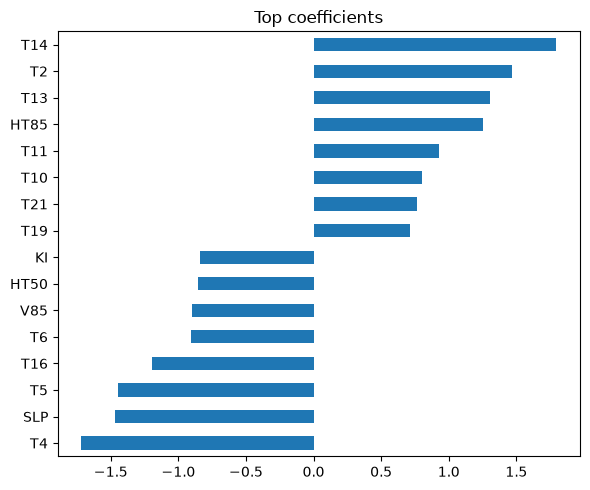

In [7]:
coefs = pd.Series(model.named_steps["clf"].coef_[0], index=features).sort_values()
pd.concat([coefs.head(8), coefs.tail(8)]).plot.barh(figsize=(6, 5)); plt.title("Top coefficients"); plt.tight_layout(); plt.show()

## Summary

**Setup:** 
Dropped 26 columns with >10% missing values (the hourly wind-speed
columns) and the 593 rows that still had nulls, leaving 1,941 rows and 46
features. Data was split chronologically 70/15/15.

**Model:** Standardized logistic regression with balanced class weights. Will act as a baseline.

**Results:**
| Split | ROC-AUC | PR-AUC |
|---|---|---|
| Train | 0.923 | 0.494 |
| Validation | 0.884 | 0.404 |
| Test | 0.913 | 0.124 |

Time-series CV (5 folds) gave a mean ROC-AUC of 0.86 and a mean PR-AUC of 0.32,
with PR-AUC varying by fold (0.17 to 0.57).

**Caveats:** The test set contains only 5 ozone days, so its PR-AUC and F1
are very noisy. The CV results are a more reliable guide.